# Mixer: dal FOM alla decisione con il ROM

**Proposta separata di riorganizzazione di `mixer.ipynb`.** Il notebook originale e `MixerFunctions.py` restano intatti. Eseguire dall'inizio con il kernel che contiene NumPy, SciPy, Matplotlib, FEniCS e dlroms.

Il percorso è: modello e dati → lifting → POD → Galerkin affine → validazione → ottimizzazione → diagnosi del candidato. Ogni sezione risponde a una domanda; i controlli tecnici sono raccolti vicino al passaggio che verificano.

I risultati si rigenerano eseguendo le celle: gli output originali non sono copiati, perché alcuni dipendono da uno stato di esecuzione incoerente. Le misure sono rispetto al FOM discreto, non alla soluzione esatta della PDE.

## 1. Modello, configurazione e convenzioni

Nel dominio rettangolare con tre cilindri risolviamo
$$-\varepsilon\Delta u+\mathbf b(\mu)\cdot\nabla u=0,\qquad
\varepsilon=0.005,\quad \mu=(c_1,c_2,c_3)\in[-5,5]^3,$$
con $\mathbf b(\mu)=\mathbf b_0+\sum_{i=1}^3c_i\mathbf b_i$. Le velocità sono precalcolate tramite Stokes. La concentrazione è imposta sul bordo sinistro: $u=g(y)=e^{-25(y-1)^2}$; la formulazione sugli altri bordi lascia il flusso diffusivo naturale nullo.

Per $v$ con traccia nulla a sinistra,
$$a_\mu(u,v)=\varepsilon\int_\Omega\nabla u\cdot\nabla v+
\int_\Omega(\mathbf b(\mu)\cdot\nabla u)v=0.$$

Gli snapshot sono colonne: `U.shape = (Nh, numero_campioni)`. POD e errori di campo usano la norma euclidea dei DOF; per una norma FEM $L^2$ servirebbe la matrice di massa. Gli errori sono conservati come frazioni e convertiti in percentuale solo in tabelle e grafici.

In [1]:
from pathlib import Path
from time import perf_counter
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import qmc
from scipy.optimize import minimize, differential_evolution
from fenics import DirichletBC, Constant, Point
import dlroms.fespaces as fe

# Supporta sia l'avvio dalla cartella Assignment1 sia dalla radice del progetto.
import sys
WORKDIR = Path.cwd() if Path("MixerFunctions.py").exists() else Path.cwd() / "Assignment1"
if not (WORKDIR / "MixerFunctions.py").exists():
    raise FileNotFoundError("Avviare il notebook dalla radice del progetto o da Assignment1.")
sys.path.insert(0, str(WORKDIR))
import MixerFunctions as mixer  # L'import costruisce mesh e quattro campi Stokes.

N_TRAIN, N_TEST = 50, 50
N_SELECTED = 25
N_OPT = 40
N_GRID = (5, 10, 15, 20, 25, 30, 35, 40)
ENERGY_THRESHOLDS = (0.95, 0.99, 0.999, 0.9999, 0.99999)
BOUNDS = [(-5.0, 5.0)] * 3
X0 = Point(1.5, 0.25)
REGENERATE_DATA = False
DATA_PATH = WORKDIR / "FOMdata_assignment1.npz"
PROPOSAL_DATA_PATH = WORKDIR / "FOMdata_mixer_proposta.npz"
Nh = mixer.Vh.dim()

# Copia difensiva: le conversioni FEM non devono modificare gli array sorgente.
def fem_function(values):
    return fe.asfunction(np.array(values, dtype=float, copy=True), mixer.Vh)

def qoi(values):
    return float(fem_function(values)(X0))

def relative_error(reference, approximation):
    denominator = np.linalg.norm(reference)
    return np.linalg.norm(reference - approximation) / denominator if denominator > 1e-14 else np.nan

def show_field(values, title, *, symmetric=False, limits=None):
    values = np.array(values, copy=True)
    if symmetric:
        scale = max(float(np.max(np.abs(values))), 1e-14)
        limits = (-scale, scale)
    kwargs = {} if limits is None else dict(vmin=limits[0], vmax=limits[1])
    plt.figure(figsize=(7, 4))
    fe.plot(values, mixer.Vh, colorbar=True, **kwargs)
    plt.title(title)
    plt.show()

Converting from Gmsh format (.msh, .gmsh) to DOLFIN XML format
Expecting 2763 vertices
Found all vertices
Expecting 5234 cells
Found all cells
Conversion done


## 2. Dataset: riuso oppure generazione, senza ricalcoli duplicati

Il training usa Latin Hypercube (seed 42); il test usa campioni uniformi indipendenti (seed 123). Il test non costruisce la base POD. Per default riutilizziamo l'archivio esistente; impostando `REGENERATE_DATA=True` generiamo e salviamo un archivio distinto, senza sovrascrivere quello originale.

I tempi caricati sono misure storiche del precedente ambiente. Per un confronto temporale sul computer attuale occorre rigenerare i dati. Controlliamo dimensioni, finitezza, campioni e valori di Dirichlet; questo non sostituisce una verifica completa dell'identità della mesh e dell'ordinamento dei DOF. Per archivi provenienti da un'altra discretizzazione occorre rigenerare.

DOF: 2763; training: (2763, 50); test: (2763, 50)
FOM test: media 0.1299 s; totale 6.49 s
FOM: tempi storici caricati; ROM: tempi della sessione corrente
Primo snapshot: min=1.389e-11, max=1


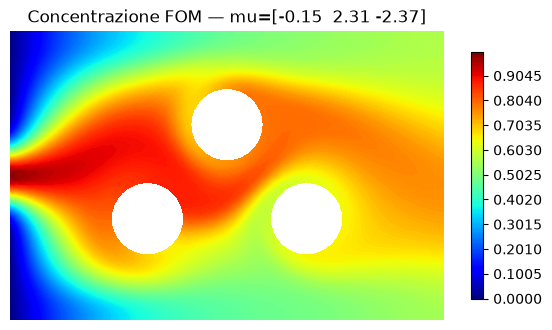

In [2]:
def solve_dataset(parameters, label):
    snapshots = np.empty((Nh, len(parameters)))
    elapsed = np.empty(len(parameters))
    for j, parameter in enumerate(parameters):
        start = perf_counter()
        snapshots[:, j] = mixer.FOMsolver(parameter)
        elapsed[j] = perf_counter() - start
    print(f"{label}: {len(parameters)} soluzioni, totale {elapsed.sum():.2f} s")
    return snapshots, elapsed

expected_train = qmc.scale(qmc.LatinHypercube(d=3, seed=42).random(N_TRAIN), [-5]*3, [5]*3)
expected_test = np.random.default_rng(123).uniform(-5, 5, (N_TEST, 3))
if DATA_PATH.exists() and not REGENERATE_DATA:
    with np.load(DATA_PATH, allow_pickle=False) as archive:
        dataset = {key: archive[key].copy() for key in
                   ("mu_train", "U_train", "mu_test", "U_test", "times_train", "times_test")}
    timing_origin = "FOM: tempi storici caricati; ROM: tempi della sessione corrente"
else:
    U_train_new, times_train_new = solve_dataset(expected_train, "Training")
    U_test_new, times_test_new = solve_dataset(expected_test, "Test")
    dataset = dict(mu_train=expected_train, U_train=U_train_new,
                   mu_test=expected_test, U_test=U_test_new,
                   times_train=times_train_new, times_test=times_test_new)
    np.savez(PROPOSAL_DATA_PATH, **dataset)
    timing_origin = "FOM e ROM misurati nella sessione corrente"

mu_train, U_train = dataset["mu_train"], dataset["U_train"]
mu_test, U_test = dataset["mu_test"], dataset["U_test"]
times_train, times_test = dataset["times_train"], dataset["times_test"]
assert U_train.shape == (Nh, N_TRAIN) and U_test.shape == (Nh, N_TEST)
assert mu_train.shape == (N_TRAIN, 3) and mu_test.shape == (N_TEST, 3)
assert times_train.shape == (N_TRAIN,) and times_test.shape == (N_TEST,)
assert all(np.isfinite(value).all() for value in dataset.values())
assert np.all(times_train > 0) and np.all(times_test > 0)
np.testing.assert_allclose(mu_train, expected_train)
np.testing.assert_allclose(mu_test, expected_test)
print(f"DOF: {Nh}; training: {U_train.shape}; test: {U_test.shape}")
print(f"FOM test: media {times_test.mean():.4f} s; totale {times_test.sum():.2f} s")
print(timing_origin)
example = U_train[:, 0]
print(f"Primo snapshot: min={example.min():.4g}, max={example.max():.4g}")
show_field(example, f"Concentrazione FOM — mu={np.round(mu_train[0], 2)}")

## 3. Lifting: rendere omogenea la condizione al bordo

Scegliamo $u_s=u_h(0,0,0)$ e definiamo $w_\mu=u_h(\mu)-u_s$. Un solo lifting basta perché $g$ non dipende da $\mu$. Sui DOF liberi,
$$A(\mu)w_\mu=-A(\mu)u_s.$$

Identifichiamo subito i DOF di Dirichlet e controlliamo la traccia degli snapshot. Il controllo della traccia è più informativo della sola identità algebrica $u_s+(u-u_s)=u$.

DOF Dirichlet: 41; traccia residua: 0.00e+00


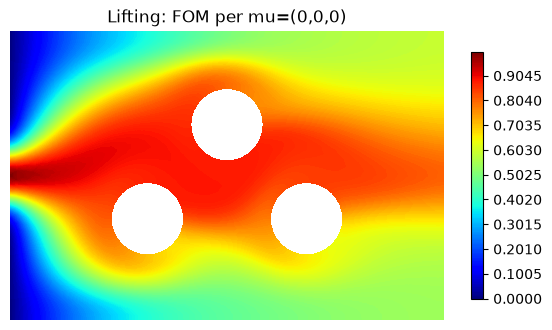

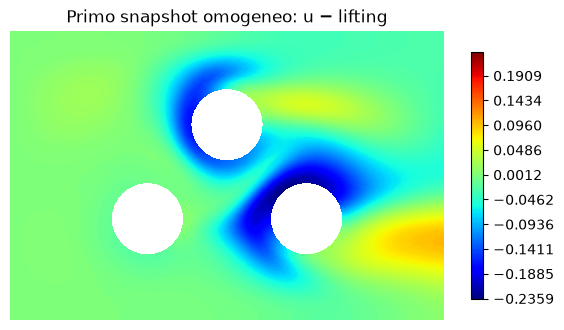

In [3]:
u_lift = mixer.FOMsolver(np.zeros(3))
bc_zero = DirichletBC(mixer.Vh, Constant(0.0),
                      lambda x, on_boundary: on_boundary and mixer.left(x))
dirichlet_dofs = np.array(sorted(bc_zero.get_boundary_values()), dtype=int)
assert len(dirichlet_dofs) > 0
W_train = U_train - u_lift[:, None]
W_test = U_test - u_lift[:, None]
trace_error = max(np.max(np.abs(W_train[dirichlet_dofs])),
                  np.max(np.abs(W_test[dirichlet_dofs])))
assert trace_error < 1e-10, "Snapshot e lifting non condividono il dato al bordo."
print(f"DOF Dirichlet: {len(dirichlet_dofs)}; traccia residua: {trace_error:.2e}")
show_field(u_lift, "Lifting: FOM per mu=(0,0,0)")
show_field(W_train[:, 0], "Primo snapshot omogeneo: u − lifting", symmetric=True)

## 4. POD: quanto rappresenta bene lo spazio ridotto?

La SVD sottile $W=U\Sigma Z^T$ produce modi euclidei ortonormali. I primi $N$ minimizzano l'errore aggregato di proiezione del training:
$$\|W-V_NV_N^TW\|_F^2=\sum_{i>N}\sigma_i^2.$$
La frazione quadratica conservata è $E_N=\sum_{i\leq N}\sigma_i^2/\sum_i\sigma_i^2$; l'errore relativo aggregato è $\sqrt{1-E_N}$. Questa «energia» non è un'energia fisica e non determina direttamente l'errore Galerkin o quello puntuale.

Non sottraiamo anche la media: il centro affine qui è il lifting. Escludiamo i modi numericamente nulli prima di usarli in un solver.

Rango numerico: 50; dimensione scelta: 25; ottimizzazione: 40
Soglia energia | N necessario | errore Frobenius training [%]
       95.000 |            5 | 20.1914
       99.000 |           10 | 9.6262
       99.900 |           21 | 2.9520
       99.990 |           34 | 0.9148
       99.999 |           44 | 0.2903


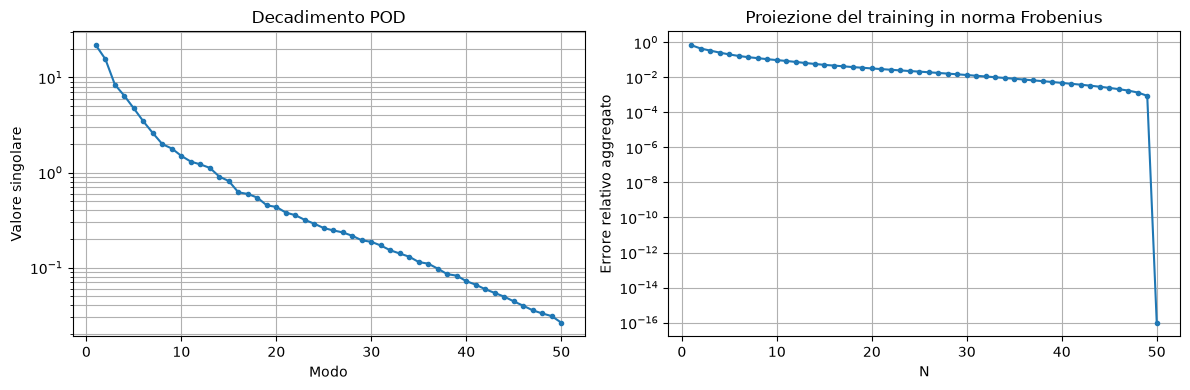

In [4]:
# Impone esattamente la traccia omogenea dopo aver verificato il dato originale.
W_train[dirichlet_dofs, :] = 0.0
W_test[dirichlet_dofs, :] = 0.0
pod_modes_all, singular_values, _ = np.linalg.svd(W_train, full_matrices=False)
tolerance = max(W_train.shape) * np.finfo(float).eps * singular_values[0]
pod_rank = int(np.count_nonzero(singular_values > tolerance))
assert pod_rank > 0
pod_modes = pod_modes_all[:, :pod_rank].copy()
pod_modes[dirichlet_dofs, :] = 0.0
np.testing.assert_allclose(pod_modes.T @ pod_modes, np.eye(pod_rank), atol=1e-10)
assert max(*N_GRID, N_SELECTED, N_OPT) <= pod_rank
energy = np.cumsum(singular_values**2) / np.sum(singular_values**2)
print(f"Rango numerico: {pod_rank}; dimensione scelta: {N_SELECTED}; ottimizzazione: {N_OPT}")
print("Soglia energia | N necessario | errore Frobenius training [%]")
for threshold in ENERGY_THRESHOLDS:
    n_required = int(np.searchsorted(energy, threshold) + 1)
    print(f"{100*threshold:13.3f} | {n_required:12d} | {100*np.sqrt(max(0, 1-energy[n_required-1])):.4f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogy(np.arange(1, len(singular_values)+1), singular_values, '.-')
axes[0].set(xlabel="Modo", ylabel="Valore singolare", title="Decadimento POD")
axes[1].semilogy(np.arange(1, len(energy)+1), np.maximum(np.sqrt(np.maximum(1-energy, 0)), 1e-16), '.-')
axes[1].set(xlabel="N", ylabel="Errore relativo aggregato", title="Proiezione del training in norma Frobenius")
for ax in axes: ax.grid(True, which="both")
plt.tight_layout(); plt.show()

Confrontiamo anche gli errori relativi **per snapshot omogeneo** sul training e sul test. La media di questi rapporti non coincide con l'errore aggregato di Frobenius: i denominatori sono diversi. Un campione omogeneo di norma quasi nulla è escluso dal rapporto e segnalato.

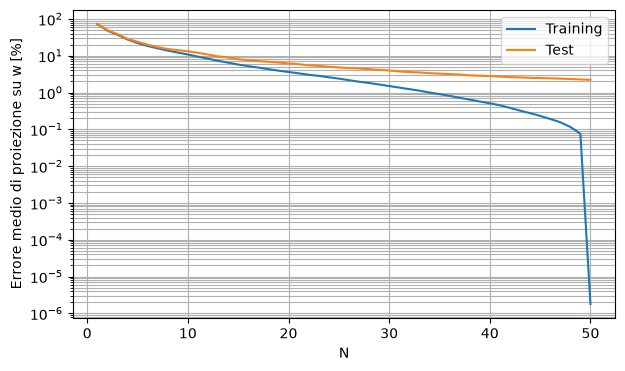

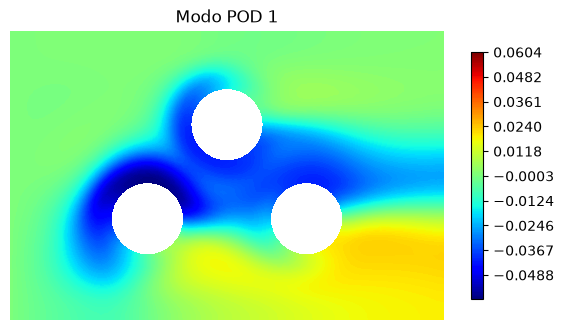

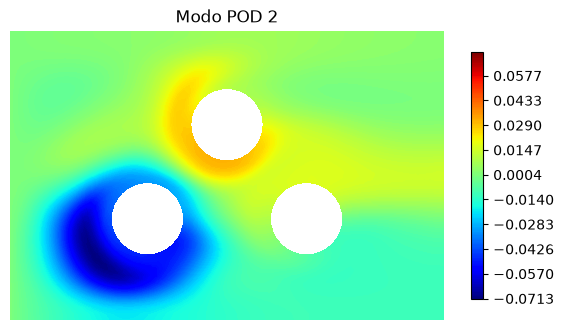

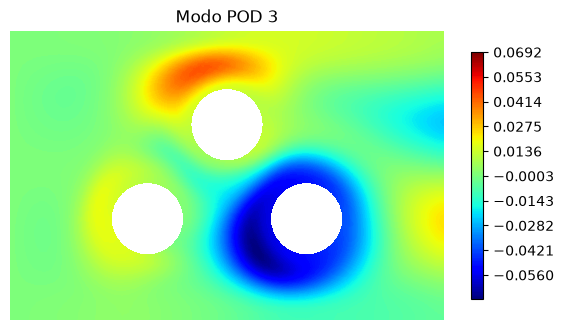

In [5]:
def projection_curve(snapshots):
    norms = np.linalg.norm(snapshots, axis=0)
    valid = norms > 1e-14
    if not np.all(valid):
        print(f"Proiezione: esclusi {np.count_nonzero(~valid)} snapshot di norma quasi nulla")
    if not np.any(valid):
        return np.full(pod_rank, np.nan)
    coefficients = pod_modes.T @ snapshots[:, valid]
    captured = np.cumsum(coefficients**2, axis=0)
    residual_squared = np.maximum(norms[valid]**2 - captured, 0.0)
    return np.mean(np.sqrt(residual_squared) / norms[valid], axis=1)

projection_train = projection_curve(W_train)
projection_test = projection_curve(W_test)
plt.figure(figsize=(7, 4))
for label, errors in (("Training", projection_train), ("Test", projection_test)):
    plt.semilogy(np.arange(1, pod_rank+1), np.maximum(100*errors, 1e-12), label=label)
plt.xlabel("N"); plt.ylabel("Errore medio di proiezione su w [%]")
plt.grid(True, which="both"); plt.legend(); plt.show()
for mode_index in range(3):
    show_field(pod_modes[:, mode_index], f"Modo POD {mode_index+1}", symmetric=True)

## 5. Galerkin affine: una sola costruzione per tutti i ROM

Gli operatori non vincolati sono $A(\mu)=A_0+\sum c_iA_i$. Cerchiamo $u_N=u_s+V_Na_N$ con
$$A_N(\mu)a_N=f_N(\mu),\quad A_{i,N}=V_N^TA_iV_N,\quad f_{i,N}=-V_N^TA_iu_s.$$
Non imponiamo righe di Dirichlet ai singoli operatori affini: i test e i modi hanno già traccia nulla. Per il lifting scelto, $f_{0,N}$ deve essere prossimo a zero.

Proiettiamo una volta sul massimo spazio richiesto; i ROM più piccoli usano i blocchi principali. Ogni oggetto conserva base, lifting, operatori e valutazioni puntuali coerenti. Cambiare una variabile di ciclo non cambia un ROM già costruito.

La quantità di interesse è $J_N(\mu)=u_N(x_0)$, $x_0=(1.5,0.25)$. Per linearità FEM, $J_N=u_s(x_0)+\phi(x_0)^Ta_N$: la valutazione online non richiede il campo completo. Prima di ottimizzare, verifichiamo questa identità contro l'interpolazione FEM diretta.

In [6]:
start = perf_counter()
affine_operators = tuple(mixer.assemble_affine_operators())
assert all(operator.shape == (Nh, Nh) for operator in affine_operators)
max_modes = max(*N_GRID, N_SELECTED, N_OPT)
max_basis = pod_modes[:, :max_modes].copy()
reduced_operators = np.stack([max_basis.T @ (operator @ max_basis)
                              for operator in affine_operators])
reduced_rhs = np.stack([-max_basis.T @ (operator @ u_lift)
                        for operator in affine_operators])
lift_at_x0 = qoi(u_lift)
modes_at_x0 = np.array([qoi(max_basis[:, j]) for j in range(max_modes)])
affine_offline_time = perf_counter() - start
print(f"Proiezioni e valutazioni puntuali offline: {affine_offline_time:.3f} s")
print(f"Norma contributo fisso del lifting: {np.linalg.norm(reduced_rhs[0]):.2e}")

@dataclass(frozen=True)
class ReducedModel:
    dimension: int
    basis: np.ndarray
    lift: np.ndarray
    operators: np.ndarray
    rhs: np.ndarray
    point_modes: np.ndarray
    point_lift: float

    def system(self, mu):
        parameter = np.asarray(mu, dtype=float)
        if parameter.shape != (3,) or not np.isfinite(parameter).all():
            raise ValueError("mu deve contenere tre parametri finiti")
        theta = np.concatenate(([1.0], parameter))
        return np.tensordot(theta, self.operators, axes=1), theta @ self.rhs

    def coefficients(self, mu):
        matrix, vector = self.system(mu)
        return np.linalg.solve(matrix, vector)

    def solve(self, mu):
        return self.lift + self.basis @ self.coefficients(mu)

    def objective(self, mu):
        return float(self.point_lift + self.point_modes @ self.coefficients(mu))

def readonly_copy(values):
    result = np.array(values, copy=True)
    result.setflags(write=False)
    return result

def build_rom(dimension):
    if not isinstance(dimension, (int, np.integer)) or not 1 <= dimension <= max_modes:
        raise ValueError(f"Dimensione richiesta fuori da [1, {max_modes}]")
    return ReducedModel(dimension, readonly_copy(max_basis[:, :dimension]),
                        readonly_copy(u_lift),
                        readonly_copy(reduced_operators[:, :dimension, :dimension]),
                        readonly_copy(reduced_rhs[:, :dimension]),
                        readonly_copy(modes_at_x0[:dimension]), lift_at_x0)

roms = {dimension: build_rom(dimension) for dimension in sorted(set(N_GRID) | {N_SELECTED, N_OPT})}
for dimension, model in roms.items():
    for parameter in (np.zeros(3), mu_test[0], mu_test[-1]):
        direct = qoi(model.solve(parameter))
        np.testing.assert_allclose(model.objective(parameter), direct, rtol=1e-10, atol=1e-11,
                                   err_msg=f"Obiettivo modale incoerente per N={dimension}")
print("Coerenza campo/modi/obiettivo verificata su tre parametri per ogni ROM.")

Proiezioni e valutazioni puntuali offline: 0.194 s
Norma contributo fisso del lifting: 1.70e-17
Coerenza campo/modi/obiettivo verificata su tre parametri per ogni ROM.


## 6. Validazione: accuratezza del campo, del punto e costo

La proiezione POD misura la capacità della base; Galerkin misura anche l'effetto delle equazioni ridotte. Qui l'errore del campo è normalizzato con la soluzione **completa** FOM, mentre la precedente curva POD era normalizzata con lo snapshot omogeneo.

Valutiamo media e massimo sui medesimi test, oltre all'errore assoluto della quantità puntuale. I tempi online del campo comprendono soluzione e ricostruzione; la quantità puntuale ha un costo separato. Il rapporto FOM/ROM esclude il costo offline e, usando l'archivio, confronta sessioni diverse. Le misure brevi sono indicative e risentono del rumore del sistema.

In [7]:
J_test = np.array([qoi(U_test[:, j]) for j in range(N_TEST)])
validation = {}
print(" N | campo medio [%] | campo max [%] | QoI abs. media | campo [ms] | QoI [ms] | rapporto FOM/ROM")
for dimension, model in roms.items():
    model.solve(mu_test[0])  # Warm-up escluso dalle misure.
    model.objective(mu_test[0])
    errors, output_errors, field_times, output_times = [], [], [], []
    for j, parameter in enumerate(mu_test):
        start = perf_counter()
        field = model.solve(parameter)
        field_times.append(perf_counter() - start)
        start = perf_counter()
        output = model.objective(parameter)
        output_times.append(perf_counter() - start)
        errors.append(relative_error(U_test[:, j], field))
        output_errors.append(abs(J_test[j] - output))
    validation[dimension] = dict(errors=np.array(errors), qoi_errors=np.array(output_errors),
                                 field_times=np.array(field_times), qoi_times=np.array(output_times))
    record = validation[dimension]
    print(f"{dimension:2d} | {100*np.mean(errors):15.3f} | {100*np.max(errors):13.3f} | "
          f"{np.mean(output_errors):14.4g} | {1000*np.mean(field_times):10.4f} | "
          f"{1000*np.mean(output_times):8.4f} | {times_test.mean()/np.mean(field_times):.1f}")
print(timing_origin)

 N | campo medio [%] | campo max [%] | QoI abs. media | campo [ms] | QoI [ms] | rapporto FOM/ROM
 5 |           4.333 |         8.730 |        0.01372 |     0.0604 |   0.0286 | 2150.0
10 |           2.573 |         5.229 |        0.01184 |     0.0407 |   0.0258 | 3187.4
15 |           1.556 |         4.043 |       0.009508 |     0.0633 |   0.0378 | 2052.8
20 |           1.221 |         3.420 |       0.006716 |     0.0406 |   0.0214 | 3198.9
25 |           0.917 |         2.960 |       0.005239 |     0.0487 |   0.0219 | 2665.6
30 |           0.793 |         2.678 |       0.005141 |     0.0543 |   0.0300 | 2392.9
35 |           0.647 |         1.911 |        0.00329 |     0.0720 |   0.0337 | 1804.2
40 |           0.547 |         1.578 |       0.003044 |     0.0693 |   0.0351 | 1875.1
FOM: tempi storici caricati; ROM: tempi della sessione corrente


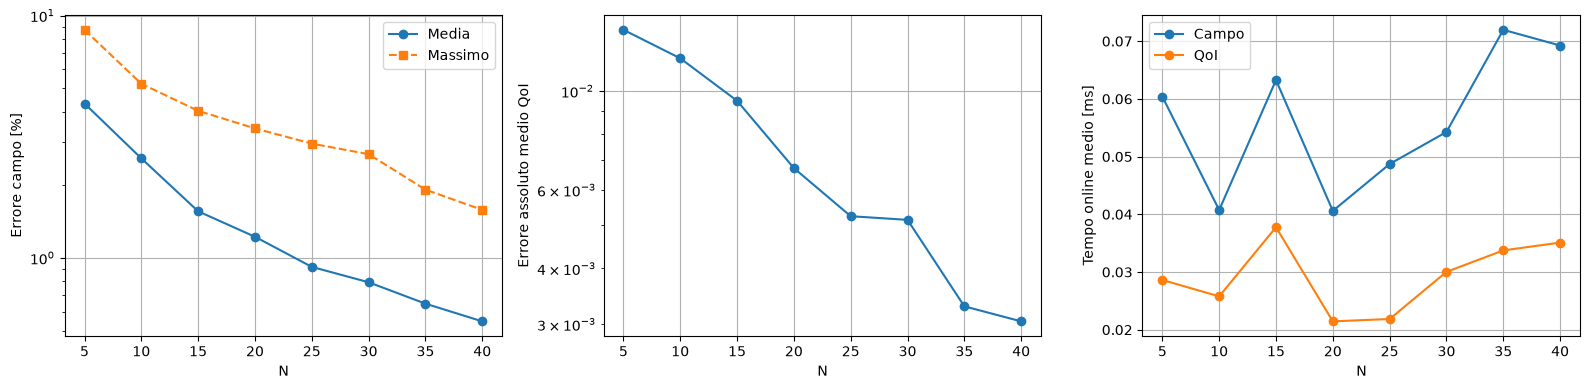

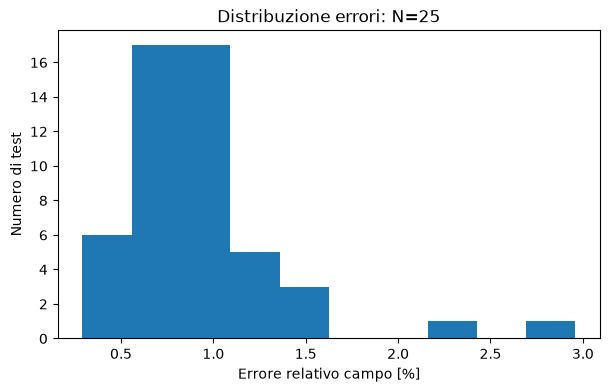

In [8]:
dimensions = sorted(validation)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].semilogy(dimensions, [100*validation[n]["errors"].mean() for n in dimensions], 'o-', label="Media")
axes[0].semilogy(dimensions, [100*validation[n]["errors"].max() for n in dimensions], 's--', label="Massimo")
axes[0].set(xlabel="N", ylabel="Errore campo [%]"); axes[0].legend()
axes[1].semilogy(dimensions, [validation[n]["qoi_errors"].mean() for n in dimensions], 'o-')
axes[1].set(xlabel="N", ylabel="Errore assoluto medio QoI")
for key, label in (("field_times", "Campo"), ("qoi_times", "QoI")):
    axes[2].plot(dimensions, [1000*validation[n][key].mean() for n in dimensions], 'o-', label=label)
axes[2].set(xlabel="N", ylabel="Tempo online medio [ms]"); axes[2].legend()
for ax in axes: ax.grid(True)
plt.tight_layout(); plt.show()
plt.figure(figsize=(7, 4))
plt.hist(100*validation[N_SELECTED]["errors"], bins=10)
plt.xlabel("Errore relativo campo [%]"); plt.ylabel("Numero di test")
plt.title(f"Distribuzione errori: N={N_SELECTED}"); plt.show()

Per un confronto spaziale leggibile, FOM e ROM condividono la scala colori. La differenza usa una scala simmetrica e resta un errore assoluto locale: dividere nodo per nodo per il FOM amplifica artificialmente le zone dove la concentrazione è quasi zero.

mu=[ 1.824 -4.462 -2.796]; errore campo=0.859%


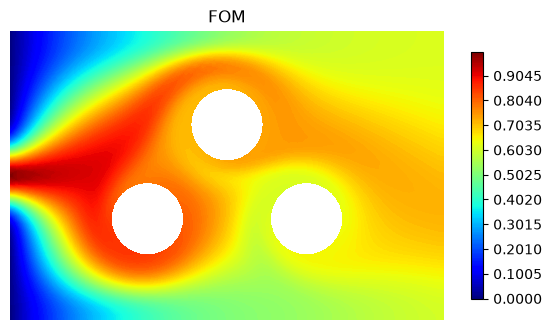

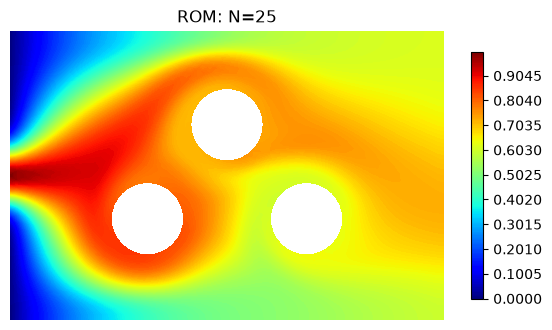

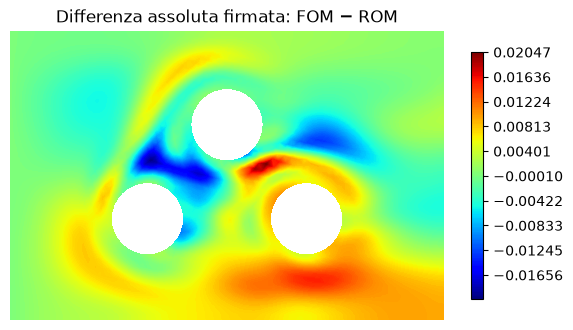

In [9]:
selected_rom = roms[N_SELECTED]
example_index = 0
fom_example = U_test[:, example_index]
rom_example = selected_rom.solve(mu_test[example_index])
common_limits = (min(fom_example.min(), rom_example.min()), max(fom_example.max(), rom_example.max()))
print(f"mu={np.round(mu_test[example_index], 3)}; errore campo={100*relative_error(fom_example, rom_example):.3f}%")
show_field(fom_example, "FOM", limits=common_limits)
show_field(rom_example, f"ROM: N={N_SELECTED}", limits=common_limits)
show_field(fom_example-rom_example, "Differenza assoluta firmata: FOM − ROM", symmetric=True)

## 7. Ottimizzazione: dalla concentrazione puntuale a un candidato

Cerchiamo $\min_{\mu\in[-5,5]^3}J_N(\mu)$. Questo obiettivo è locale e non misura l'omogeneità globale del mixing. Usiamo esplicitamente il ROM `N_OPT`, indipendentemente dall'ultima dimensione dei cicli.

Confrontiamo Nelder–Mead dal centro, multistart da 21 punti e differential evolution. Le stesse partenze sono riutilizzate nel confronto tra dimensioni. Riportiamo stato, valutazioni e obiettivo: la convergenza dell'algoritmo non certifica il minimo globale. Un candidato senza convergenza resta visibile, ma la selezione finale privilegia risultati convergenti e finiti.

In [10]:
starts = np.vstack([np.zeros(3), np.random.default_rng(42).uniform(-5, 5, (20, 3))])
local_options = dict(maxiter=500, xatol=1e-6, fatol=1e-8)

def local_search(model, initial):
    return minimize(model.objective, initial, method="Nelder-Mead", bounds=BOUNDS, options=local_options)

def choose_candidate(results):
    finite = [result for result in results if np.isfinite(result.fun)]
    converged = [result for result in finite if result.success]
    if not finite:
        raise RuntimeError("Nessun candidato con obiettivo finito")
    if not converged:
        print("Nessuna ricerca convergente: candidato provvisorio con obiettivo finito.")
    return min(converged or finite, key=lambda result: result.fun)

def multistart(model):
    results = [local_search(model, initial) for initial in starts]
    return choose_candidate(results), results

optimization_rom = roms[N_OPT]
local_result = local_search(optimization_rom, starts[0])
multistart_result, local_runs = multistart(optimization_rom)
global_result = differential_evolution(optimization_rom.objective, bounds=BOUNDS,
                                       seed=42, tol=1e-8, polish=True)
search_results = {"Locale dal centro": local_result, "Multistart": multistart_result,
                  "Differential evolution": global_result}
print(f"N={N_OPT}; riferimento J(0)={optimization_rom.objective(np.zeros(3)):.8f}")
for label, result in search_results.items():
    print(f"{label}: mu={np.round(result.x, 5)}, J_ROM={result.fun:.8f}, "
          f"success={result.success}, nfev={result.nfev}")
    print(f"  Arresto: {result.message}")
print(f"Multistart: {sum(result.success for result in local_runs)}/{len(local_runs)} ricerche convergenti")
final_candidate = choose_candidate(list(search_results.values()))

N=40; riferimento J(0)=0.51660403
Locale dal centro: mu=[-0.96338  1.05508 -0.42443], J_ROM=0.46640959, success=True, nfev=389
  Arresto: Optimization terminated successfully.
Multistart: mu=[-1.18975 -5.      -4.87878], J_ROM=0.40991126, success=True, nfev=215
  Arresto: Optimization terminated successfully.
Differential evolution: mu=[-1.1897  -5.      -4.87894], J_ROM=0.40991126, success=True, nfev=2749
  Arresto: Optimization terminated successfully.
Multistart: 21/21 ricerche convergenti


## 8. Validazione FOM e sensibilità alla dimensione

La validazione valuta il FOM **allo stesso parametro** del candidato ROM: non è un'ottimizzazione FOM. Conserviamo insieme dimensione, candidato e risultato, senza sostituire un solver globale. Gli errori puntuali assoluti sono sempre riportati; quelli relativi diventano `NaN` se il riferimento è quasi nullo.

Il test è usato qui per confrontare prestazioni e il migliore campione disponibile; non certifica l'ottimo sul dominio continuo. Se queste analisi vengono usate per scegliere dimensione o arricchire il training, un ulteriore insieme indipendente serve per la valutazione finale.

In [11]:
fom_cache = {}
def cached_fom(parameter):
    key = tuple(np.asarray(parameter, dtype=float))
    if key not in fom_cache:
        fom_cache[key] = mixer.FOMsolver(np.asarray(parameter, dtype=float))
    return fom_cache[key]

def validate_candidate(model, result):
    reference = cached_fom(result.x)
    J_fom = qoi(reference)
    J_rom = model.objective(result.x)
    absolute = abs(J_fom-J_rom)
    return dict(N=model.dimension, mu=result.x.copy(), success=bool(result.success),
                J_rom=J_rom, J_fom=J_fom, abs_error=absolute,
                rel_error=absolute/abs(J_fom) if abs(J_fom)>1e-14 else np.nan)

candidate_validation = validate_candidate(optimization_rom, final_candidate)
print("Candidato selezionato:", candidate_validation)
best_test_index = int(np.argmin(J_test))
print(f"Migliore campione FOM test: mu={mu_test[best_test_index]}, J={J_test[best_test_index]:.8f}")

optimization_by_dimension = []
for dimension in N_GRID:
    model = roms[dimension]
    if dimension == N_OPT:
        result = multistart_result
    else:
        result, _ = multistart(model)
    record = validate_candidate(model, result)
    optimization_by_dimension.append(record)
    print(f"N={dimension:2d} | mu={np.round(record['mu'], 3)} | ROM={record['J_rom']:.6f} | "
          f"FOM={record['J_fom']:.6f} | err.abs={record['abs_error']:.4g} | "
          f"err.rel={100*record['rel_error']:.2f}% | success={record['success']}")

Candidato selezionato: {'N': 40, 'mu': array([-1.18975461, -5.        , -4.87877645]), 'success': True, 'J_rom': 0.40991125537920925, 'J_fom': 0.4136196526762148, 'abs_error': 0.003708397297005561, 'rel_error': 0.008965718318777585}
Migliore campione FOM test: mu=[-1.87257744 -4.85525523 -4.67448078], J=0.43338186
N= 5 | mu=[-1.527  0.008 -2.233] | ROM=0.391296 | FOM=0.472440 | err.abs=0.08114 | err.rel=17.18% | success=True
N=10 | mu=[-1.696  4.651 -5.   ] | ROM=0.386769 | FOM=0.450482 | err.abs=0.06371 | err.rel=14.14% | success=True
N=15 | mu=[-1.212  5.    -3.874] | ROM=0.414221 | FOM=0.455487 | err.abs=0.04127 | err.rel=9.06% | success=True
N=20 | mu=[-1.111 -5.    -4.891] | ROM=0.397715 | FOM=0.413275 | err.abs=0.01556 | err.rel=3.77% | success=True
N=25 | mu=[-1.161 -5.    -3.78 ] | ROM=0.407758 | FOM=0.424038 | err.abs=0.01628 | err.rel=3.84% | success=True
N=30 | mu=[-1.249 -5.    -4.389] | ROM=0.383405 | FOM=0.418854 | err.abs=0.03545 | err.rel=8.46% | success=True
N=35 | mu=

## 9. Diagnosi unica del candidato: base, Galerkin e copertura

Fissiamo il candidato finale per distinguere l'effetto di $N$ dallo spostamento del parametro ottimizzato. Confrontiamo:

- la proiezione euclidea $u_{proj}=u_s+V_NV_N^T(u_h-u_s)$, riferimento ottimale per il campo nella base;
- la soluzione Galerkin, che impone l'ortogonalità del residuo e può avere errori non monotoni;
- la quantità puntuale, che non è minimizzata dalla proiezione euclidea;
- il residuo proiettato, i coefficienti e la coerenza tra valutazione modale e FEM.

Il residuo degli operatori non vincolati può essere non nullo sulle righe di Dirichlet: misuriamo anche le righe libere. Un residuo piccolo controlla la consistenza, non certifica l'accuratezza. Le distanze ai campioni descrivono la copertura del training e non sono stime d'errore.

In [12]:
mu_diagnostic = final_candidate.x.copy()
u_diagnostic = cached_fom(mu_diagnostic)
w_diagnostic = u_diagnostic-u_lift
J_reference = qoi(u_diagnostic)
print("Parametro fisso:", mu_diagnostic)
print(" N | proiezione campo [%] | Galerkin campo [%] | J_proiezione | J_Galerkin | J_FOM")
for dimension in N_GRID:
    model = roms[dimension]
    a_projection = model.basis.T @ w_diagnostic
    projected = model.lift + model.basis @ a_projection
    galerkin = model.solve(mu_diagnostic)
    print(f"{dimension:2d} | {100*relative_error(u_diagnostic, projected):20.3f} | "
          f"{100*relative_error(u_diagnostic, galerkin):18.3f} | {qoi(projected):12.6f} | "
          f"{model.objective(mu_diagnostic):10.6f} | {J_reference:.6f}")

model = optimization_rom
a_galerkin = model.coefficients(mu_diagnostic)
a_projection = model.basis.T @ w_diagnostic
field = model.solve(mu_diagnostic)
J_direct = qoi(field)
J_modal = model.point_lift + model.point_modes @ a_galerkin
J_objective = model.objective(mu_diagnostic)
np.testing.assert_allclose([J_modal, J_objective], J_direct, rtol=1e-10, atol=1e-11)
theta = np.concatenate(([1.0], mu_diagnostic))
A_mu = sum(weight*operator for weight, operator in zip(theta, affine_operators))
residual = A_mu @ u_diagnostic
free_dofs = np.setdiff1d(np.arange(Nh), dirichlet_dofs)
AN, fN = model.system(mu_diagnostic)
print(f"Residuo FOM sui DOF liberi: {np.linalg.norm(residual[free_dofs]):.3e}")
print(f"Residuo FOM proiettato: {np.linalg.norm(model.basis.T @ residual):.3e}")
print(f"Residuo ridotto: {np.linalg.norm(AN @ a_galerkin-fN):.3e}")
print(f"Condizionamento euclideo A_N: {np.linalg.cond(AN):.3e}")
print(f"Differenza relativa coefficienti proiezione/Galerkin: {relative_error(a_projection, a_galerkin):.3e}")
print(f"QoI diretta={J_direct:.10f}; modale={J_modal:.10f}; objective={J_objective:.10f}")
distances = np.linalg.norm(mu_train-mu_diagnostic, axis=1)
print("Cinque training più vicini: parametro | distanza | J_FOM")
for index in np.argsort(distances)[:5]:
    print(f"{np.round(mu_train[index], 3)} | {distances[index]:.3f} | {qoi(U_train[:, index]):.6f}")

Parametro fisso: [-1.18975461 -5.         -4.87877645]
 N | proiezione campo [%] | Galerkin campo [%] | J_proiezione | J_Galerkin | J_FOM
 5 |                6.511 |              8.877 |     0.486449 |   0.485643 | 0.413620
10 |                3.589 |              5.501 |     0.435810 |   0.469932 | 0.413620
15 |                2.737 |              4.242 |     0.425071 |   0.440136 | 0.413620
20 |                2.296 |              3.933 |     0.420166 |   0.398132 | 0.413620
25 |                2.175 |              3.229 |     0.415316 |   0.417015 | 0.413620
30 |                1.390 |              2.741 |     0.403301 |   0.384583 | 0.413620
35 |                0.996 |              1.697 |     0.410197 |   0.414638 | 0.413620
40 |                0.791 |              1.419 |     0.410015 |   0.409911 | 0.413620
Residuo FOM sui DOF liberi: 1.959e-16
Residuo FOM proiettato: 2.158e-17
Residuo ridotto: 4.497e-18
Condizionamento euclideo A_N: 5.961e+01
Differenza relativa coefficienti pr

## 10. Come leggere i risultati e proseguire

La soglia POD descrive la rappresentazione del training. La tabella di validazione descrive campo e quantità puntuale su campioni indipendenti. La verifica del candidato descrive l'affidabilità della decisione in quel parametro. Queste tre informazioni vanno lette insieme: un buon errore medio di campo non basta a garantire una buona ottimizzazione puntuale.

Se il candidato resta poco accurato, il passo successivo è arricchire il training nella sua regione e ripetere lifting/POD/proiezioni/validazione con nuovi oggetti ROM. Se la proiezione è buona ma Galerkin resta molto peggiore, approfondire stabilità e condizionamento della formulazione. Per interpretazioni fisiche, considerare POD e errori con matrice di massa e verificare anche la discretizzazione FOM.

Le dimensioni in configurazione sono scelte di confronto, non dichiarazioni di ottimalità. I risultati numerici e il compromesso costo/accuratezza vanno commentati dopo l'esecuzione nel kernel del progetto.

## Appendice — revisione del notebook originale

I riferimenti seguenti usano l'indice delle celle nel file, **a partire da zero**.

| Celle originali | Osservazione | Proposta applicata |
|---|---|---|
| 6, 8, 16 | Il primo parametro training viene risolto tre volte. | Visualizzare lo snapshot già disponibile. |
| 8–14 | Cicli training/test duplicati, log lunghi, dimensioni e tempi frammentati. | Un helper di generazione e un riepilogo compatto. |
| 18–21 | Salvataggio seguito subito da caricamento; stampa isolata dello snapshot. | Un ramo riuso/generazione; nuovo archivio separato. |
| 24–30 | Lifting mostrato due volte; identità di ricostruzione quasi tautologica. | Una visualizzazione e verifica effettiva della traccia. |
| 36–45 | Scale lineari/log e grafici di energia parzialmente sovrapposti. Il testo di 41 annuncia 20 modi e un campione, il codice analizza tutte le dimensioni e tutti gli snapshot. | Spettro, errore Frobenius e curva train/test con denominatori espliciti. |
| 40, 42, 80, 109, 117 | `N` viene sovrascritto dai cicli; basi e solver non si aggiornano insieme. | Dimensioni di ciclo locali e ROM conservati per dimensione. |
| 50 | DOF di Dirichlet individuati ma non usati per verificare i modi. | Verifica del bordo prima della POD e traccia esattamente nulla. |
| 52–78 | Stessa costruzione ripetuta manualmente e nella factory; quattro operatori trattati separatamente; doppio controllo di `f0N`. | Una decomposizione affine, proiezione massima e factory unica. |
| 76 | Titolo “FOM − ROM” ma codice divide per il FOM locale, potenzialmente quasi nullo. | Differenza firmata assoluta, colori comuni per i due campi. |
| 80–90 | Metriche e tempi in celle separate; etichette senza `%`; testo con N=20 e codice con N=25. | Tabella unica, grafici complementari, selezione centralizzata. |
| 78, 93, 103–105 | Obiettivo ridefinito; valutazioni dei modi precalcolate ma inutilizzate; costo online dipendente da Nh. | Obiettivo modale associato al ROM, verificato prima dell'uso. |
| 101, 105–109 | Il candidato resta quello del precedente ROM, mentre il solver può cambiare dimensione. | Ogni validazione riceve insieme modello e candidato. |
| 117–135 | Parametro critico hardcoded, stessi FOM e controlli ricalcolati; diagnosi disperse. | Candidato corrente, cache FOM e diagnosi unica. |
| 133–135 | Output modale incoerente: 0.536814 contro 0.409911; l'ultima verifica diretta/objective non verifica la formula modale. | Assert fra tutte le modalità, copie difensive e stop in caso di discrepanza. La causa originale richiede esecuzione pulita e ispezione di `fe.asfunction`. |

**Limite della verifica di questa proposta:** struttura JSON e sintassi Python verificabili senza il kernel scientifico; esecuzione FEM completa necessaria nell'ambiente del progetto. Le copie difensive prevengono possibili effetti collaterali della conversione, ma non dimostrano che siano la causa dell'incoerenza originale.